<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Standard%20Problem%204_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Mumax⁺ in Google Colaboratory**

# About Google Colaboratory

Google Colaboratory is a research tool mainly used by researchers in the field of machine learning. The main purpose of this tool is to run Python code in Jupyter notebooks. These notebooks run on a virtual Linux machine private to your Gmail account. This means that you will need a Gmail account to execute programs in a Google Colaboratory session. If you have a Gmail account you should be able to copy this Jupyter notebook to your Google Drive and execute the code cells.

Run the cell below to connect to a GPU-enabled Colaboratory runtime and display its details.

In [1]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

This machine runs Linux with Python 3.13.16 and provides the following GPU/CUDA specs:
Sun Nov  8 17:34:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |          

# Installing mumax⁺

To run mumax⁺ simulations, the `mumaxplus` Python package must be installed in this Colab environment. To this end, we will make our life easy by using the appropriate pre-built wheel provided in the mumax⁺ GitHub release assets. Running the cell below will install mumax⁺, which may take a minute to complete. When the installation is done, you can collapse this section to get a clean workspace.

In [2]:
try:
    import google.colab
except ImportError:
    pass
else:
    !uv pip install mumaxplus

Using Python 3.13.16 environment at: /usr
Resolved 15 packages in 719ms
Prepared 2 packages in 18.55s
Installed 2 packages in 2ms
 + mumaxplus==1.2.2
 + pyovf==0.3.0


# Running mumax+

Now it's up to you! The example below solves Standard Problem 4 using mumax⁺, but feel free to create a copy of this notebook to solve another micromagnetic problem of your choice.

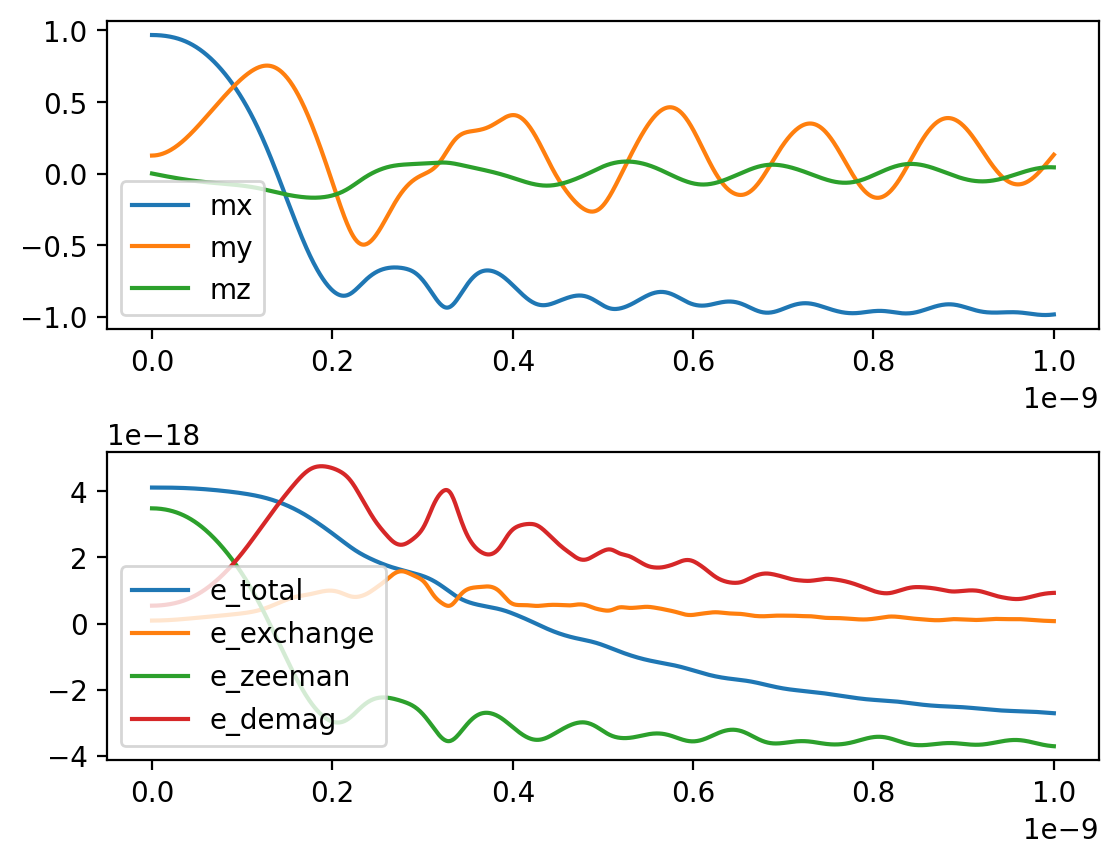

In [8]:
# This script solves micromagnetic Standard Problem 4. The Problem specification
# can be found on https://www.ctcms.nist.gov/~rdm/mumag.org.html

import matplotlib.pyplot as plt
import numpy as np

from mumaxplus import Ferromagnet, Grid, World

plt.rcParams['figure.dpi'] = 200

length, width, thickness = 500e-9, 125e-9, 3e-9
nx, ny, nz = 128, 32, 1
world = World(cellsize=(length / nx, width / ny, thickness / nz))

magnet = Ferromagnet(world, Grid((nx, ny, nz)))
magnet.msat = 800e3
magnet.aex = 13e-12
magnet.alpha = 0.02

magnet.magnetization = (1, 0.1, 0)
magnet.minimize()

B1 = (-24.6e-3, 4.3e-3, 0)
B2 = (-35.5e-3, -6.3e-3, 0)
world.bias_magnetic_field = B1  # choose B1 or B2 here

# --- SCHEDULE THE OUTPUT ---
timepoints = np.linspace(0, 1e-9, 1000)
outputquantities = {
    "mx": lambda: magnet.magnetization.average()[0],
    "my": lambda: magnet.magnetization.average()[1],
    "mz": lambda: magnet.magnetization.average()[2],
    "e_total": magnet.total_energy,
    "e_exchange": magnet.exchange_energy,
    "e_zeeman": magnet.zeeman_energy,
    "e_demag": magnet.demag_energy
}

# --- RUN THE SOLVER ---
output = world.timesolver.solve(timepoints, outputquantities)

# --- PLOT THE OUTPUT DATA ---
plt.subplot(211)
for key in ["mx", "my", "mz"]:
    plt.plot(output["time"], output[key], label=key)
plt.legend()

plt.subplot(212)
for key in ["e_total", "e_exchange", "e_zeeman", "e_demag"]:
    plt.plot(timepoints, output[key], label=key)
plt.legend()

plt.subplots_adjust(hspace=0.4)
plt.show()